# Lambda2 x Depth Tuning for CSET

`lambda2-tuning.ipynb` swept `lambda2` for `CSET` and `MCE` jointly, at a fixed,
hardcoded `depth=0.8` (the shared `wCSET`/`CSET`/`MCE` base class default -- never
itself tuned). `harmonic-prior-tuning.ipynb` ran into exactly this same "fixed,
arbitrary depth" problem for `wCSET`'s `beta`, and found that `beta` and `depth`
interact rather than being independently tunable -- the same risk applies here:
tuning `lambda2` alone at a fixed `depth` could land on a `lambda2` that's only
optimal for that one `depth`.

This notebook narrows to `CSET` only (dropping `MCE` -- whether the same joint
tuning matters for `MCE` is a separate follow-up, not this notebook's scope) and
sweeps `lambda2` **and** `depth` jointly, same `beta x depth`-style joint grid as
`harmonic-prior-tuning.ipynb`, using the same subject/run setup and `MetricSuite`
conventions as `lambda2-tuning.ipynb`.

**Restricted to hrp/pp only, not a full time-window correlation metric**, same
reason as `lambda2-tuning.ipynb`: `CSET`'s cost scales with the number of
timepoints in the data passed to `.solve()` (confirmed there: ~3.7s/solve on a
2-timepoint `phase_data` array), so this stays restricted to the two solved
timepoints (half-rising-phase, peak-phase) rather than a full cropped window.

**Grids**:
- `lambda2_values = [0.01, 0.03, 0.1, 0.3, 1.0]` -- unchanged from `lambda2-tuning.ipynb`
  (5 log-spaced values centered on the `0.1` codebase default), since this notebook
  only adds a second dimension, not a wider `lambda2` range. (`lambda2-tuning.ipynb`'s
  own recommendation flagged `1.0` as the sweep's edge with the true optimum
  possibly higher -- still true here, not addressed by this notebook.)
- `depths = [0, 0.2, 0.5, 0.8, 1.0]` -- same grid as `harmonic-prior-tuning.ipynb`'s
  joint sweep, same rationale (0 = no weighting, 0.8 = class default, the rest for
  range).

Projected cost: 10 runs x 5 lambda2 x 5 depths x ~3.7s/solve (CSET only, no MCE) ~
~15-16 minutes.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import mindmap as mm
import mne

from mindmap.analysis.functional.common.metric import find_peak_localization_error
from mindmap.analysis.simulation.engine import Simulator
from mindmap.core.metric import calc_correlation

dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"
runs = [str(r) for r in range(1, 11)]

fwd = dm.load(sub, "fwd", desc="inv")
eig = dm.load(sub, "eig")
eigvec, eigval = eig["vec"], eig["val"]

simulator, _, _ = Simulator.load(dm.roots["sim"]/f"sub-{sub}"/"simulator")
dipole_positions = mm.anatomy.source_space.get_dipole_positions(fwd["src"]) * 1000

tmin, tmax = -0.05, 0.15
lambda2_values = [0.01, 0.03, 0.1, 0.3, 1.0]
depths = [0, 0.2, 0.5, 0.8, 1.0]


## Solve and evaluate across runs x lambda2 x depth (CSET only)

For each run: crop to the response window, locate half-rising-phase/peak-phase on
the cropped `ave`, build a 2-timepoint `phase_data` array (not the full crop) --
that's what actually gets passed to `.solve()`, keeping every solve cheap
regardless of the crop window's own length. Score against that run's own `gold`:
AP (precision-recall) at hrp and pp, spatial correlation (across dipoles) at hrp/pp,
and peak-localization-error at hrp -- same metrics, same construction as
`lambda2-tuning.ipynb`.

Registered into `metrics` under `label=f"lambda2={lambda2}"` (no method prefix needed
now that only `CSET` is being swept) with `depth=depth` carried as an extra per-entry
coordinate tag, same convention `harmonic-prior-tuning.ipynb` uses for `beta`/`depth`.


In [2]:
metrics = mm.metric.MetricSuite(f"Lambda2 x Depth Tuning {sub} (CSET)")
scalar_rows = []

for run in tqdm(runs, desc="runs"):
    ave = dm.load(sub, "ave", run=run)
    ncov = dm.load(sub, "cov", run=run)
    gold = dm.load(sub, "gold", run=run)
    src_seed = dm.load(sub, "source", run=run)

    data = ave.copy().crop(tmin=tmin, tmax=tmax)
    ground = gold.copy().crop(tmin=tmin, tmax=tmax)
    hrp_idx = mm.analysis.eeg.get_rising_phase(data, ratio=0.5, as_idx=True)[0]
    pp_idx = mm.analysis.eeg.get_rising_phase(data, ratio=1, as_idx=True)[0]
    phase_data = mne.EvokedArray(data.data[:, [hrp_idx, pp_idx]], data.info, tmin=0, nave=ave.nave, kind=ave.kind)

    gold_hrp = ground.data[:, hrp_idx]
    gold_pp = ground.data[:, pp_idx]
    gold_phase = np.stack([gold_hrp, gold_pp], axis=1)   # (n_dipoles, 2), same layout as sol.data
    true_source_mask = src_seed.select_targets(simulator.hm.src, simulator.hm.parc, simulator.hm.ras2tkras)

    def evaluate_and_register(label, sol, depth):
        sol_hrp, sol_pp = sol.data[:, 0], sol.data[:, 1]

        ap_hrp = mm.core.calc_pr_curve(gold_hrp > 0, sol_hrp)["ap"]
        ap_pp = mm.core.calc_pr_curve(gold_pp > 0, sol_pp)["ap"]
        metrics.register("ap_hrp", ap_hrp, Label=label, depth=depth)
        metrics.register("ap_pp", ap_pp, Label=label, depth=depth)

        # spatial correlation (across dipoles) at hrp/pp individually -- axis=0
        # correlates along the dipole axis at each of the 2 timepoints, same
        # "spatial" mode harmonic-prior-tuning.ipynb uses over a full window
        corr = calc_correlation(gold_phase, sol.data, method="pearson", axis=0)
        corr_hrp, corr_pp = corr[0], corr[1]
        metrics.register("spatial_correlation_hrp", corr_hrp, Label=label, depth=depth)
        metrics.register("spatial_correlation_pp", corr_pp, Label=label, depth=depth)

        hit_hrp = find_peak_localization_error(sol_hrp, true_source_mask, dipole_positions)
        metrics.register("localization_error_hrp", hit_hrp["distance_mm"], Label=label, depth=depth)

        return ap_hrp, ap_pp, corr_hrp, corr_pp, hit_hrp["distance_mm"]

    for lambda2 in lambda2_values:
        for depth in depths:
            inv_cset = mm.analysis.inverse.CSET(forward=fwd, noise_cov=ncov, depth=depth, eigenvectors=eigvec)
            sol_cset = inv_cset.solve(phase_data, lambda2=lambda2)
            ap_hrp, ap_pp, corr_hrp, corr_pp, loc_err_hrp = evaluate_and_register(f"lambda2={lambda2}", sol_cset, depth)
            scalar_rows.append(dict(
                run=run, method="cset", lambda2=lambda2, depth=depth,
                ap_hrp=ap_hrp, ap_pp=ap_pp, corr_hrp=corr_hrp, corr_pp=corr_pp, loc_err_hrp=loc_err_hrp,
            ))

scalar_df = pd.DataFrame(scalar_rows)
scalar_df.to_csv("cset_lambda2_depth_tuning_outcomes.tsv", sep="\t", index=False)
print(f"{len(scalar_df)} (run, lambda2, depth) rows.")

runs:   0%|          | 0/10 [00:00<?, ?it/s]

runs:  10%|█         | 1/10 [02:41<24:12, 161.37s/it]

runs:  20%|██        | 2/10 [05:48<23:30, 176.30s/it]

runs:  30%|███       | 3/10 [08:38<20:13, 173.39s/it]

runs:  40%|████      | 4/10 [10:17<14:24, 144.15s/it]

runs:  50%|█████     | 5/10 [11:28<09:48, 117.69s/it]

... (3 outputs left out)

runs:  90%|█████████ | 9/10 [20:10<02:09, 129.77s/it]

runs: 100%|██████████| 10/10 [21:28<00:00, 113.87s/it]

runs: 100%|██████████| 10/10 [21:28<00:00, 128.84s/it]

250 (run, lambda2, depth) rows.


## Visualization

Joint `lambda2 x depth` tuning landscape: mean and std, across the 10 runs, for
each scalar metric -- same heatmap-grid approach `harmonic-prior-tuning.ipynb` uses
for its `beta x depth` grid (a box plot per `(lambda2, depth)` cell, as
`lambda2-tuning.ipynb` used for its 1D sweep, would mean 25 boxes per metric --
unreadable at this grid size). No depth-faceted time-course plot here (unlike
`harmonic-prior-tuning.ipynb`): CSET is only solved at 2 timepoints (hrp, pp), not
a full cropped window, so there's no time-series metric to facet.


Summary (mean +/- std across the 10 runs):


ap_hrp               ap_pp            corr_hrp            \
                   mean       std      mean       std      mean       std   
lambda2 depth                                                               
0.01    0.0    0.321686  0.059515  0.733198  0.100237  0.236731  0.047641   
        0.2    0.329443  0.060099  0.729726  0.101816  0.244690  0.049129   
        0.5    0.335247  0.059760  0.723537  0.105480  0.246178  0.059011   
        0.8    0.326991  0.062840  0.716982  0.109940  0.236228  0.070112   
        1.0    0.316933  0.065714  0.713106  0.113373  0.226196  0.077010   
0.03    0.0    0.403508  0.047351  0.754611  0.088104  0.368927  0.055413   
        0.2    0.402529  0.049645  0.746375  0.092867  0.370593  0.056138   
        0.5    0.387182  0.055530  0.734162  0.101778  0.354238  0.070158   
        0.8    0.361019  0.064604  0.723479  0.111068  0.321946  0.088580   
        1.0    0.343440  0.070085  0.717530  0.116959  0.297932  0.098055   
0.10    0.0    0.500345  0.054835  0.779603  0.068269  0.487469  0.058582   
        0.2    0.486331  0.062707  0.767827  0.076675  0.482117  0.054467   
        0.5    0.455621  0.071085  0.749033  0.090562  0.454201  0.079435   
        0.8    0.409670  0.075793  0.731033  0.104379  0.400007  0.111911   
        1.0    0.380364  0.077375  0.722342  0.112792  0.355809  0.125690   
0.30    0.0    0.537326  0.053091  0.801278  0.056322  0.507189  0.063123   
        0.2    0.523124  0.065135  0.786899  0.062189  0.503459  0.050812   
        0.5    0.496872  0.078778  0.763179  0.075009  0.484665  0.075344   
        0.8    0.444633  0.086315  0.734097  0.093656  0.420525  0.118743   
        1.0    0.403213  0.085468  0.721354  0.103060  0.364224  0.137806   
1.00    0.0    0.523019  0.060584  0.793911  0.063793  0.463078  0.068536   
        0.2    0.520999  0.060430  0.771669  0.069358  0.462751  0.052460   
        0.5    0.499952  0.061717  0.751732  0.077178  0.451540  0.035878   
        0.8    0.447823  0.080965  0.735941  0.087291  0.405996  0.100298   
        1.0    0.412669  0.087484  0.720527  0.094788  0.363159  0.148629   

                corr_pp           loc_err_hrp             
                   mean       std        mean        std  
lambda2 depth                                             
0.01    0.0    0.332077  0.032701   14.867689  12.023446  
        0.2    0.324286  0.029091   20.975849  28.127922  
        0.5    0.294617  0.032229    5.790563   5.517914  
        0.8    0.252896  0.044563   22.208426  15.458480  
        1.0    0.224571  0.053636   22.306261  18.109744  
0.03    0.0    0.467245  0.046122   13.234505  10.516732  
        0.2    0.449275  0.040139    9.486015  11.002330  
        0.5    0.395904  0.037834   17.839670  23.804046  
        0.8    0.327364  0.048116   20.930660  23.439504  
        1.0    0.282025  0.057502   19.052462   9.680137  
0.10    0.0    0.604651  0.057307   10.797146  10.583939  
        0.2    0.577967  0.054236    7.817052   9.453986  
        0.5    0.501707  0.049501   11.662844  10.319908  
        0.8    0.400121  0.046205   18.123164  10.876402  
        1.0    0.334087  0.052307   20.621681  11.463990  
0.30    0.0    0.672066  0.046580   10.015234  10.272839  
        0.2    0.642399  0.049809    9.762562   9.084694  
        0.5    0.565889  0.056332   15.874190   8.227322  
        0.8    0.446902  0.049905   20.998303  11.300066  
        1.0    0.368862  0.043725   20.931690  12.451363  
1.00    0.0    0.642429  0.039813   11.941354  10.186618  
        0.2    0.603167  0.051548   12.089905   9.919606  
        0.5    0.539509  0.057868   16.267343  10.714648  
        0.8    0.462154  0.062090   18.925512   9.565840  
        1.0    0.390340  0.063867   20.615109  12.558682

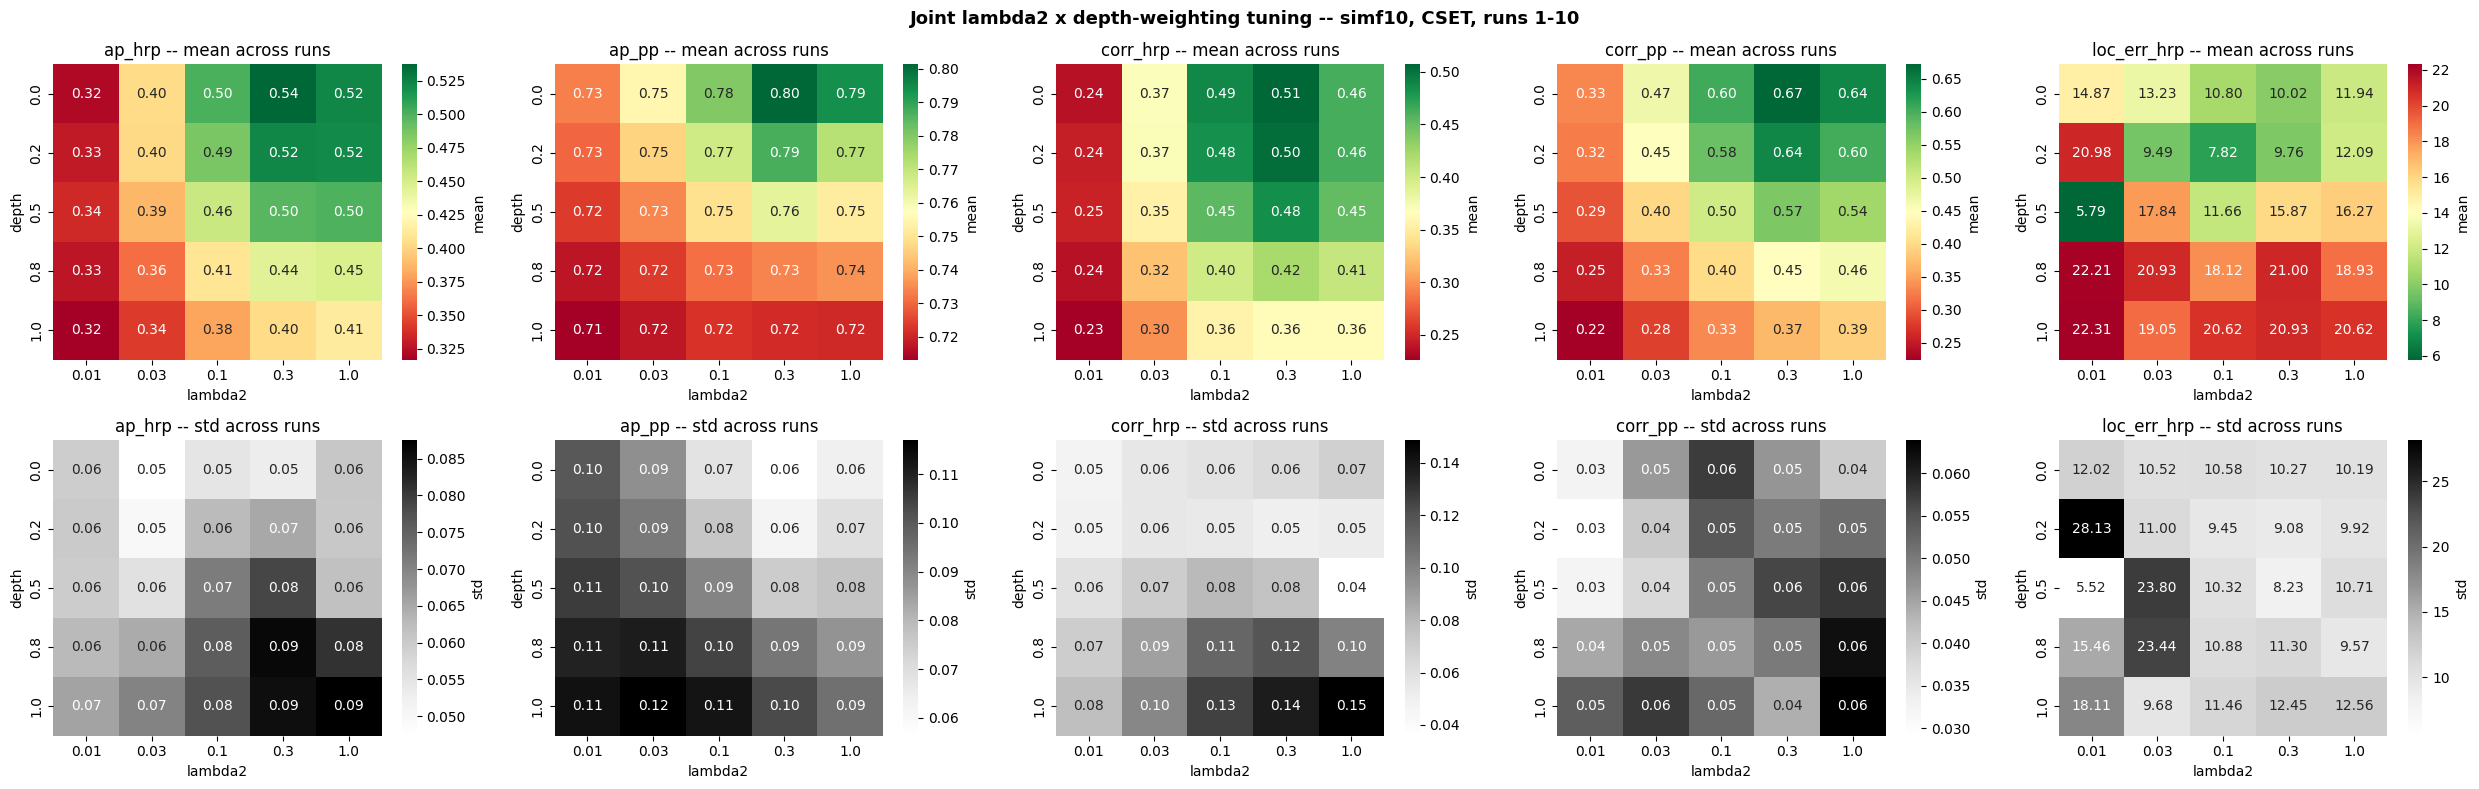

In [3]:
scalar_metrics = [
    ("ap_hrp", "RdYlGn"),               # higher is better
    ("ap_pp", "RdYlGn"),                # higher is better
    ("corr_hrp", "RdYlGn"),             # higher is better
    ("corr_pp", "RdYlGn"),              # higher is better
    ("loc_err_hrp", "RdYlGn_r"),        # lower is better -- reversed colormap
]

fig, axes = plt.subplots(2, len(scalar_metrics), figsize=(5 * len(scalar_metrics), 8))
for col, (metric, cmap) in enumerate(scalar_metrics):
    mean_grid = scalar_df.pivot_table(index="depth", columns="lambda2", values=metric, aggfunc="mean")
    std_grid = scalar_df.pivot_table(index="depth", columns="lambda2", values=metric, aggfunc="std")

    sns.heatmap(mean_grid, annot=True, fmt=".2f", cmap=cmap, ax=axes[0, col], cbar_kws={"label": "mean"})
    axes[0, col].set_title(f"{metric} -- mean across runs")

    sns.heatmap(std_grid, annot=True, fmt=".2f", cmap="Greys", ax=axes[1, col], cbar_kws={"label": "std"})
    axes[1, col].set_title(f"{metric} -- std across runs")

fig.suptitle(
    f"Joint lambda2 x depth-weighting tuning -- {sub}, CSET, runs {runs[0]}-{runs[-1]}",
    fontsize=13, fontweight="bold",
)
fig.tight_layout()
fig.savefig("cset_lambda2_depth_tuning.png", dpi=130, bbox_inches="tight")

print("Summary (mean +/- std across the 10 runs):")
scalar_df.groupby(["lambda2", "depth"])[["ap_hrp", "ap_pp", "corr_hrp", "corr_pp", "loc_err_hrp"]].agg(["mean", "std"])
